# Section 5 — European Call Option Pricing

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad
from scipy.special import logsumexp

DAYS = 252
INPUT_DIR = Path('research_data')
OUTPUT_DIR = Path('option_results')
TICKERS = ['META', 'XOM']
MATURITIES_DAYS = [21, 126]
MONEYNESS = [0.9, 1.0, 1.1]
R, Q = (0.04, 0.0)
TRUNC_LOW, TRUNC_HIGH = (0.001, 0.999)
N_PATHS = 20000
SEED = 2026

In [17]:
def load_exported_models(ticker, input_dir=INPUT_DIR):
    params_file = input_dir / 'fitted_models_2021_2023.csv'
    spots_file = input_dir / 'valuation_spots_2023.csv'
    for file in (params_file, spots_file):
        if not file.exists():
            raise FileNotFoundError(f'Missing {file}. Run the export cell in the fitting notebook first.')
    parameters = pd.read_csv(params_file)
    spots = pd.read_csv(spots_file)
    matches = parameters.loc[parameters['ticker'] == ticker]
    spot_matches = spots.loc[spots['ticker'] == ticker]
    if len(matches) != 1 or len(spot_matches) != 1:
        raise ValueError(f'{ticker}: expected exactly one parameter row and one spot row')
    row, spot = (matches.iloc[0], spot_matches.iloc[0])
    weights = np.array([row['gmm_weight_1'], row['gmm_weight_2']], dtype=float)
    means = np.array([row['gmm_mean_1'], row['gmm_mean_2']], dtype=float)
    sds = np.array([row['gmm_std_1'], row['gmm_std_2']], dtype=float)
    if not np.isclose(weights.sum(), 1, atol=1e-06) or np.any(weights <= 0):
        raise ValueError(f'{ticker}: invalid GMM weights')
    if np.any(sds <= 0) or row['normal_sigma'] <= 0 or row['t_scale'] <= 0:
        raise ValueError(f'{ticker}: invalid fitted scales')
    fits = {'normal': (float(row['normal_mu']), float(row['normal_sigma'])), 'gmm': (weights, means, sds), 'student_t': (float(row['t_df']), float(row['t_loc']), float(row['t_scale']))}
    return (fits, float(spot['spot']), str(spot['valuation_date']), int(row['n_train']))

In [18]:
stock_inputs = {}

for ticker in TICKERS:
    fits, s0, date, n_train = load_exported_models(ticker)
    stock_inputs[ticker] = {'fits': fits, 's0': s0, 'date': date, 'n_train': n_train}
    print(f"{ticker}: spot={s0:.2f}, date={date}, n_train={n_train}, Student-t df={fits['student_t'][0]:.3f}")

stock_inputs[TICKERS[0]]['fits']

META: spot=350.60, date=2023-12-29, n_train=752, Student-t df=3.428
XOM: spot=91.43, date=2023-12-29, n_train=752, Student-t df=11.683


{'normal': (0.0003652865187250068, 0.03024885614589466),
 'gmm': (array([0.06480858, 0.93519142]),
  array([-0.00786176,  0.00093542]),
  array([0.08776059, 0.02096772])),
 'student_t': (3.4279341736908338,
  0.0010567161142437836,
  0.018158452954129642)}

## Truncated Student-t: cutting edge

In [19]:
def prepare_truncated_t(params, p_low=TRUNC_LOW, p_high=TRUNC_HIGH):
    if not 0 < p_low < p_high < 1:
        raise ValueError('Require 0 < p_low < p_high < 1')
    df, loc, scale = params
    a = stats.t.ppf(p_low, df, loc=loc, scale=scale)
    b = stats.t.ppf(p_high, df, loc=loc, scale=scale)
    moment_integral, error = quad(lambda x: np.exp(x) * stats.t.pdf(x, df, loc=loc, scale=scale), a, b, epsabs=1e-11, epsrel=1e-09)
    moment = moment_integral / (p_high - p_low)
    return {'low': a, 'high': b, 'moment': moment, 'c': np.log(moment), 'integration_error': error, 'p_low': p_low, 'p_high': p_high}

truncation = {ticker: prepare_truncated_t(stock_inputs[ticker]['fits']['student_t']) for ticker in TICKERS}

pd.DataFrame(truncation).T

,low,high,moment,c,integration_error,p_low,p_high
META,-0.153829,0.155942,1.001395,0.001394,7.259510e-14,0.001,0.999
XOM,-0.067073,0.069981,1.001630,0.001629,3.061312e-10,0.001,0.999


## Risk-neutral drift adjustments for three distributions

In [20]:
def log_exponential_moment(model, params, trunc=None):
    if model == 'normal':
        mu, sigma = params
        return mu + 0.5 * sigma ** 2
    if model == 'gmm':
        weights, means, sds = params
        return float(logsumexp(np.log(weights) + means + 0.5 * sds ** 2))
    if model == 'student_t_truncated':
        if trunc is None:
            raise ValueError('Truncation settings required for Student-t')
        return trunc['c']
    raise ValueError(f'Unknown model: {model}')

for ticker in TICKERS:
    fits = stock_inputs[ticker]['fits']
    print(ticker, {m: round(log_exponential_moment(m, fits[k], truncation[ticker]), 8) for m, k in [('normal', 'normal'), ('gmm', 'gmm'), ('student_t_truncated', 'student_t')]})

META {'normal': 0.00082278, 'gmm': 0.00082125, 'student_t_truncated': np.float64(0.00139436)}
XOM {'normal': 0.00152562, 'gmm': 0.00152551, 'student_t_truncated': np.float64(0.00162879)}


## Extract a sample of daily returns

In [21]:
def sample_daily_returns(model, params, shape, rng, trunc=None):
    if model == 'normal':
        mu, sigma = params
        return rng.normal(mu, sigma, size=shape)
    if model == 'gmm':
        weights, means, sds = params
        component = rng.choice(len(weights), size=shape, p=weights)
        return rng.normal(means[component], sds[component])
    if model == 'student_t_truncated':
        if trunc is None:
            raise ValueError('Truncation settings required')
        df, loc, scale = params
        u = rng.uniform(trunc['p_low'], trunc['p_high'], size=shape)
        return stats.t.ppf(u, df, loc=loc, scale=scale)
    raise ValueError(model)

rng = np.random.default_rng(SEED)
ticker = TICKERS[0]
fits = stock_inputs[ticker]['fits']

for model, key in [('normal', 'normal'), ('gmm', 'gmm'), ('student_t_truncated', 'student_t')]:
    x = sample_daily_returns(model, fits[key], 5000, rng, truncation[ticker])
    print(f'{model:22s} mean={x.mean():+.5f} std={x.std():.5f} min={x.min():+.4f} max={x.max():+.4f}')

normal                 mean=+0.00014 std=0.03037 min=-0.1130 max=+0.1099
gmm                    mean=+0.00044 std=0.02828 min=-0.2315 max=+0.2306
student_t_truncated    mean=+0.00057 std=0.02547 min=-0.1459 max=+0.1529


## Single-step martingale condition: numerical self-check

In [22]:
ticker = TICKERS[0]
fits = stock_inputs[ticker]['fits']
rng = np.random.default_rng(SEED)
target = np.exp((R - Q) / DAYS)
checks = []

for model, key in [('normal', 'normal'), ('gmm', 'gmm'), ('student_t_truncated', 'student_t')]:
    x = sample_daily_returns(model, fits[key], 30000, rng, truncation[ticker])
    c = log_exponential_moment(model, fits[key], truncation[ticker])
    growth = np.exp((R - Q) / DAYS + x - c)
    se = growth.std(ddof=1) / np.sqrt(len(growth))
    checks.append({'model': model, 'simulated_growth': growth.mean(), 'theoretical_growth': target, 'MC_standard_error': se, 'difference_in_SE': (growth.mean() - target) / se})

pd.DataFrame(checks)

,model,simulated_growth,theoretical_growth,MC_standard_error,difference_in_SE
0,normal,1.000154,1.000159,0.000175,-0.026494
1,gmm,1.000286,1.000159,0.000176,0.725689
2,student_t_truncated,1.000012,1.000159,0.000152,-0.970126


## Generating Future Stock Price Paths from Daily Returns

In [23]:
def simulate_terminal_growth(model, params, n_days, n_paths, rate, dividend_yield, rng, trunc=None, batch_size=12000):
    c = log_exponential_moment(model, params, trunc)
    chunks = []
    for start in range(0, n_paths, batch_size):
        size = min(batch_size, n_paths - start)
        raw = sample_daily_returns(model, params, (size, n_days), rng, trunc)
        log_growth = ((rate - dividend_yield) / DAYS + raw - c).sum(axis=1)
        chunks.append(np.exp(log_growth))
    return np.concatenate(chunks)

ticker = TICKERS[0]
rng = np.random.default_rng(SEED)
growth_demo = simulate_terminal_growth('normal', stock_inputs[ticker]['fits']['normal'], 21, 5000, R, Q, rng)

print('Mean terminal growth:', growth_demo.mean())
print('Risk-neutral target:', np.exp((R - Q) * 21 / DAYS))

Mean terminal growth: 1.0026216025027626
Risk-neutral target: 1.0033388950668758


## Calculating Call Options, Monte Carlo Errors, and Delta Using Stock Prices at Expiration

In [24]:
def price_call_from_growth(s0, strike, n_days, rate, growth):
    terminal_spot = s0 * growth
    payoff = np.maximum(terminal_spot - strike, 0.0)
    discount = np.exp(-rate * n_days / DAYS)
    price = discount * payoff.mean()
    mc_se = discount * payoff.std(ddof=1) / np.sqrt(len(payoff))
    delta = discount * np.mean(growth * (terminal_spot > strike))
    return {'call': price, 'mc_se': mc_se, 'delta': delta}

s0 = stock_inputs[ticker]['s0']
price_call_from_growth(s0, s0, 21, R, growth_demo)

{'call': np.float64(19.50376410857502),
 'mc_se': np.float64(0.43379271914630846),
 'delta': np.float64(0.5330353509318577)}

## Black–Scholes

In [25]:
def bs_call_delta(s0, strike, n_days, rate, dividend_yield, sigma_daily):
    T = n_days / DAYS
    vol = sigma_daily * np.sqrt(DAYS)
    if s0 <= 0 or strike <= 0 or T <= 0 or (vol <= 0):
        raise ValueError('Spot, strike, maturity and volatility must be positive')
    d1 = (np.log(s0 / strike) + (rate - dividend_yield + 0.5 * vol ** 2) * T) / (vol * np.sqrt(T))
    d2 = d1 - vol * np.sqrt(T)
    call = s0 * np.exp(-dividend_yield * T) * stats.norm.cdf(d1) - strike * np.exp(-rate * T) * stats.norm.cdf(d2)
    delta = np.exp(-dividend_yield * T) * stats.norm.cdf(d1)
    return {'call': call, 'mc_se': 0.0, 'delta': delta}

bs_call_delta(s0, s0, 21, R, Q, stock_inputs[ticker]['fits']['normal'][1])

{'call': np.float64(19.929648495882134),
 'mc_se': 0.0,
 'delta': np.float64(0.5371895459339499)}

## Main experiment: 2 stocks × 2 times × 3 strike prices × 4 methods

In [26]:
MODEL_SPECS = [('Gaussian MC', 'normal', 'normal'), ('GMM', 'gmm', 'gmm'), ('Truncated Student-t', 'student_t_truncated', 'student_t')]

results = []

for ticker in TICKERS:
    info = stock_inputs[ticker]
    s0, fits = (info['s0'], info['fits'])
    for n_days in MATURITIES_DAYS:
        simulated = {}
        for label, model, key in MODEL_SPECS:
            model_id = [x[0] for x in MODEL_SPECS].index(label)
            ticker_id = TICKERS.index(ticker)
            maturity_id = MATURITIES_DAYS.index(n_days)
            rng = np.random.default_rng(np.random.SeedSequence([SEED, ticker_id, maturity_id, model_id]))
            simulated[label] = simulate_terminal_growth(model, fits[key], n_days, N_PATHS, R, Q, rng, truncation[ticker])
        for ratio in MONEYNESS:
            strike = s0 * ratio
            bs = bs_call_delta(s0, strike, n_days, R, Q, fits['normal'][1])
            results.append(dict(ticker=ticker, valuation_date=info['date'], days=n_days, strike_over_spot=ratio, spot=s0, strike=strike, model='Black-Scholes', **bs))
            for label, _, _ in MODEL_SPECS:
                estimate = price_call_from_growth(s0, strike, n_days, R, simulated[label])
                results.append(dict(ticker=ticker, valuation_date=info['date'], days=n_days, strike_over_spot=ratio, spot=s0, strike=strike, model=label, **estimate))
    print(f'Finished {ticker}')

results_df = pd.DataFrame(results)

display(results_df.head(12))

Finished META
Finished XOM


,ticker,valuation_date,days,strike_over_spot,spot,strike,model,call,mc_se,delta
0,META,2023-12-29,21,0.9,350.60199,315.541791,Black-Scholes,41.791728,0.000000,0.803291
1,META,2023-12-29,21,0.9,350.60199,315.541791,Gaussian MC,41.855636,0.293660,0.804604
2,META,2023-12-29,21,0.9,350.60199,315.541791,GMM,41.758837,0.289181,0.817783
3,META,2023-12-29,21,0.9,350.60199,315.541791,Truncated Student-t,39.778611,0.257533,0.837386
4,META,2023-12-29,21,1.0,350.60199,350.601990,Black-Scholes,19.929648,0.000000,0.537190
5,META,2023-12-29,21,1.0,350.60199,350.601990,Gaussian MC,19.978352,0.220753,0.535984
6,META,2023-12-29,21,1.0,350.60199,350.601990,GMM,19.390802,0.219396,0.540786
7,META,2023-12-29,21,1.0,350.60199,350.601990,Truncated Student-t,16.921006,0.187995,0.534290
8,META,2023-12-29,21,1.1,350.60199,385.662189,Black-Scholes,7.720087,0.000000,0.276182
9,META,2023-12-29,21,1.1,350.60199,385.662189,Gaussian MC,7.739975,0.140847,0.272919


## Result Verification: Gaussian MC vs Black–Scholes

In [27]:
pivot = results_df.pivot_table(index=['ticker', 'days', 'strike_over_spot'], columns='model', values=['call', 'mc_se', 'delta'])

check = pd.DataFrame(index=pivot.index)
check['BS_call'] = pivot['call', 'Black-Scholes']
check['Gaussian_MC_call'] = pivot['call', 'Gaussian MC']
check['MC_SE'] = pivot['mc_se', 'Gaussian MC']
check['price_diff_in_SE'] = (check['Gaussian_MC_call'] - check['BS_call']) / check['MC_SE'].clip(lower=1e-12)
check['BS_delta'] = pivot['delta', 'Black-Scholes']
check['Gaussian_MC_delta'] = pivot['delta', 'Gaussian MC']

display(check.round(5))

print('Max absolute standardized price difference:', round(check['price_diff_in_SE'].abs().max(), 2))

BS_call  Gaussian_MC_call    MC_SE  \
ticker days strike_over_spot                                        
META   21   0.9               41.79173          41.85564  0.29366   
            1.0               19.92965          19.97835  0.22075   
            1.1                7.72009           7.73998  0.14085   
       126  0.9               68.09852          68.14374  0.68918   
            1.0               50.34827          50.24801  0.61536   
            1.1               36.59226          36.35163  0.53955   
XOM    21   0.9                9.79931           9.85441  0.05246   
            1.0                3.32506           3.37513  0.03586   
            1.1                0.62337           0.64766  0.01588   
       126  0.9               13.91544          13.66964  0.11447   
            1.0                8.62896           8.44887  0.09539   
            1.1                4.99071           4.88723  0.07491   

                              price_diff_in_SE  BS_delta  Gaussian_MC_delta  
ticker days strike_over_spot                                                 
META   21   0.9                        0.21763   0.80329            0.80460  
            1.0                        0.22063   0.53719            0.53598  
            1.1                        0.14120   0.27618            0.27292  
       126  0.9                        0.06562   0.70505            0.70797  
            1.0                       -0.16292   0.59044            0.59588  
            1.1                       -0.44599   0.47925            0.48171  
XOM    21   0.9                        1.05044   0.90173            0.90415  
            1.0                        1.39642   0.53261            0.53406  
            1.1                        1.52969   0.15567            0.15937  
       126  0.9                       -2.14722   0.75624            0.75205  
            1.0                       -1.88804   0.57942            0.56761  
            1.1                       -1.38129   0.40272            0.39407

Max absolute standardized price difference: 2.15


## Plot and save

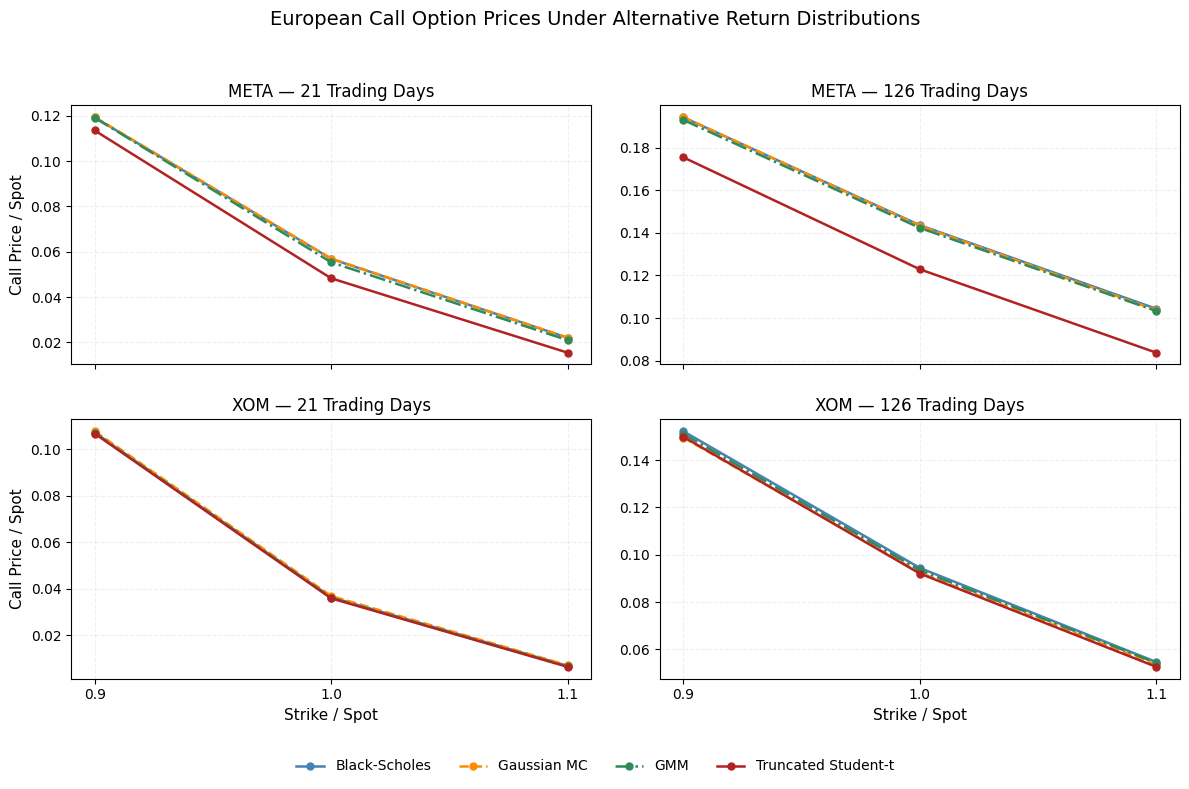

In [31]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(OUTPUT_DIR / 'option_price_comparison.csv', index=False)

parameter_diagnostics = []


fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex=True,
    sharey=False
)


# Consistent colors and line styles

model_colors = {
    'Black-Scholes': 'steelblue',
    'Gaussian MC': 'darkorange',
    'GMM': 'seagreen',
    'Truncated Student-t': 'firebrick'
}

model_linestyles = {
    'Black-Scholes': '-',
    'Gaussian MC': '--',
    'GMM': '-.',
    'Truncated Student-t': '-'
}



for i, ticker in enumerate(TICKERS):

    for j, n_days in enumerate(MATURITIES_DAYS):

        ax = axes[i, j]

        subset = results_df[
            (results_df['ticker'] == ticker) &
            (results_df['days'] == n_days)
        ]


        for model, group in subset.groupby('model', sort=False):

            group = group.sort_values('strike_over_spot')

            ax.plot(
                group['strike_over_spot'],
                group['call'] / group['spot'],
                marker='o',
                markersize=5,
                linewidth=1.8,
                color=model_colors[model],
                linestyle=model_linestyles[model],
                label=model
            )


        # Panel title

        ax.set_title(
            f'{ticker} — {n_days} Trading Days',
            fontsize=12
        )


        # Axis labels

        if i == 1:
            ax.set_xlabel('Strike / Spot', fontsize=11)

        if j == 0:
            ax.set_ylabel('Call Price / Spot', fontsize=11)


        # Axis formatting

        ax.set_xticks([0.9, 1.0, 1.1])

        ax.grid(
            alpha=0.2,
            linestyle='--'
        )

        ax.tick_params(labelsize=10)


handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    fontsize=10
)


fig.suptitle(
    'European Call Option Prices Under Alternative Return Distributions',
    fontsize=14,
    y=0.98
)

fig.tight_layout(
    rect=[0, 0.07, 1, 0.95],
    h_pad=2.0,
    w_pad=2.0
)


fig.savefig(
    OUTPUT_DIR / 'combined_option_price_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

fig.savefig(
    OUTPUT_DIR / 'combined_option_price_comparison.pdf',
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

In [29]:
# Compare option prices relative to Black-Scholes

price_comparison = results_df.pivot_table(
    index=['ticker', 'days', 'strike_over_spot'],
    columns='model',
    values='call'
)


# Percentage difference relative to Black-Scholes

relative_difference = (
    price_comparison.div(
        price_comparison['Black-Scholes'],
        axis=0
    ) - 1
) * 100


# Black-Scholes is the reference model

relative_difference = relative_difference.drop(
    columns='Black-Scholes'
)


display(relative_difference.round(2))

model                          GMM  Gaussian MC  Truncated Student-t
ticker days strike_over_spot                                        
META   21   0.9              -0.08         0.15                -4.82
            1.0              -2.70         0.24               -15.10
            1.1              -4.84         0.26               -29.91
       126  0.9              -0.64         0.07                -9.67
            1.0              -0.89        -0.20               -14.42
            1.1              -1.03        -0.66               -19.75
XOM    21   0.9              -0.05         0.56                -0.38
            1.0              -0.44         1.51                -1.31
            1.1              -2.91         3.90                -5.87
       126  0.9              -0.75        -1.77                -1.54
            1.0              -1.05        -2.09                -2.51
            1.1              -0.70        -2.07                -3.75

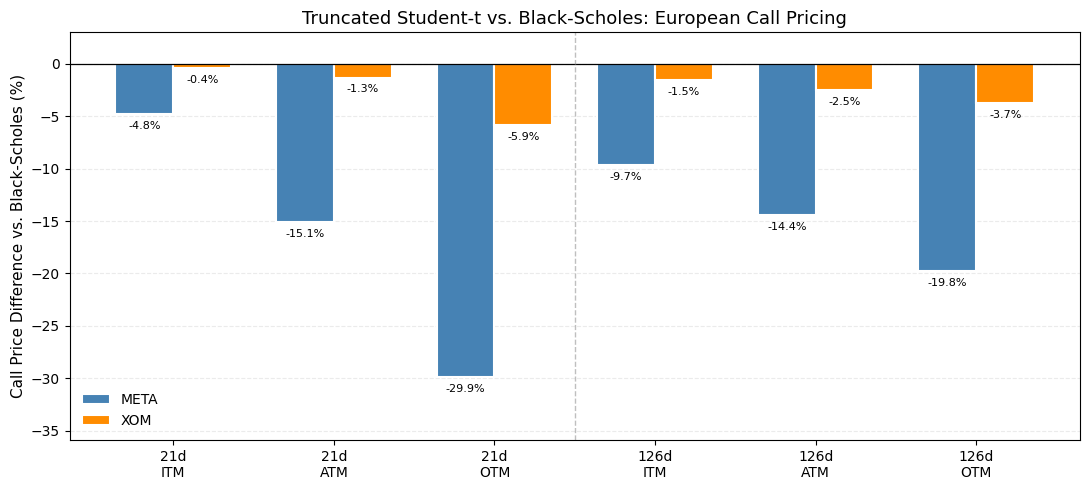

In [30]:

strike_levels = [0.9, 1.0, 1.1]

maturities = [21, 126]

strike_labels = {
    0.9: 'ITM',
    1.0: 'ATM',
    1.1: 'OTM'
}


meta_differences = []
xom_differences = []

x_labels = []


for days in maturities:

    for strike in strike_levels:

        meta_value = relative_difference.loc[
            ('META', days, strike),
            'Truncated Student-t'
        ]

        xom_value = relative_difference.loc[
            ('XOM', days, strike),
            'Truncated Student-t'
        ]

        meta_differences.append(meta_value)

        xom_differences.append(xom_value)

        x_labels.append(
            f'{days}d\n{strike_labels[strike]}'
        )



fig, ax = plt.subplots(
    figsize=(11, 5)
)

x = np.arange(len(x_labels))

width = 0.36


bars_meta = ax.bar(
    x - width / 2,
    meta_differences,
    width,
    label='META',
    color='steelblue',
    edgecolor='white',
    linewidth=1.5
)


bars_xom = ax.bar(
    x + width / 2,
    xom_differences,
    width,
    label='XOM',
    color='darkorange',
    edgecolor='white',
    linewidth=1.5
)


for bars in [bars_meta, bars_xom]:

    for bar in bars:

        value = bar.get_height()

        ax.annotate(
            f'{value:.1f}%',
            xy=(
                bar.get_x() + bar.get_width() / 2,
                value
            ),
            xytext=(0, -5),
            textcoords='offset points',
            ha='center',
            va='top',
            fontsize=8
        )


ax.axhline(
    0,
    color='black',
    linewidth=0.9
)

ax.axvline(
    2.5,
    color='gray',
    linestyle='--',
    linewidth=1,
    alpha=0.5
)

ax.set_xticks(x)

ax.set_xticklabels(
    x_labels,
    fontsize=10
)

ax.set_ylabel(
    'Call Price Difference vs. Black-Scholes (%)',
    fontsize=11
)

ax.set_title(
    'Truncated Student-t vs. Black-Scholes: European Call Pricing',
    fontsize=13
)

ax.set_ylim(
    min(meta_differences + xom_differences) * 1.20,
    3
)

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.25
)

ax.set_axisbelow(True)

ax.legend(
    frameon=False,
    fontsize=10,
    loc='lower left'
)


plt.tight_layout()

plt.savefig(
    'student_t_vs_bs_call_pricing.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()